# 08 — DAEs, quadratures, and sensitivities

**Objectives.** Form a semi-explicit index-1 DAE, integrate it with IDAS, and differentiate the terminal state. A semi-explicit DAE has $\dot x=f(x,z,p)$ and $0=g(x,z,p)$. IDAS needs a consistent algebraic initial guess; high-index DAEs generally require reformulation.


In [1]:
# Make repository-local helpers importable without installing a package.
import sys
from pathlib import Path

repository_root = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "casadi_tutorial").is_dir()
)
if str(repository_root) not in sys.path:
    sys.path.insert(0, str(repository_root))

# Autoreload picks up edits to tutorial models before each notebook cell runs.
ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic("load_ext", "autoreload")
    ipython.run_line_magic("autoreload", "2")

### Integrate an index-one differential-algebraic system

This cell describes a DAE using CasADi's `x`, `z`, `p`, `ode`, `alg`, and
`quad` fields. `ca.integrator` selects IDAS, which advances the differential
state while enforcing the algebraic residual. The quadrature state
accumulates an integral without adding it to the physical state vector.

The model is

$$
\dot x=-z,\qquad
0=z^2-x-p,\qquad
\dot q=x^2.
$$

Therefore the returned quadrature is

$$
q(t_f)=\int_{0}^{t_f}x(t)^2\,dt.
$$

The final assertion checks the algebraic consistency condition
$z_f^2-x_f-p=0$ for $p=0$.

The time-history figure shows the differential state $x(t)$, algebraic variable $z(t)$, and accumulated quadrature $q(t)$, so algebraic consistency and integral accumulation can be inspected over time.


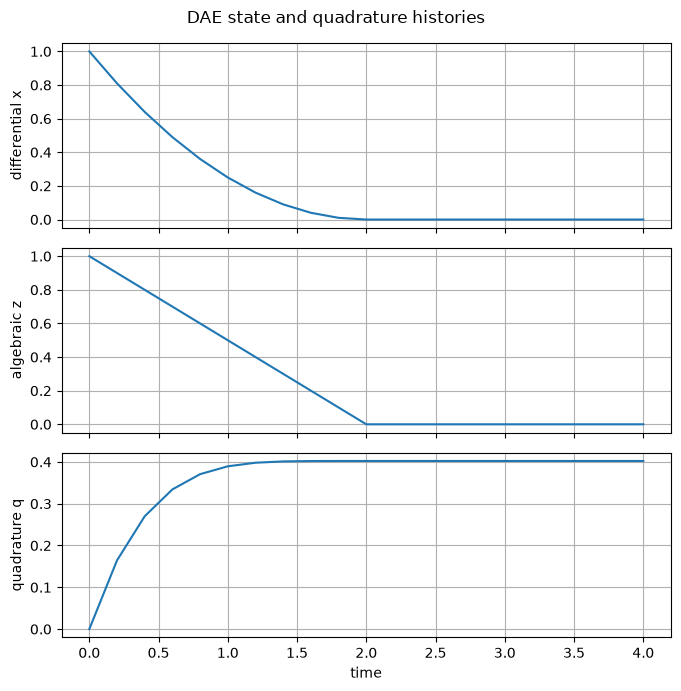

In [2]:
import casadi as ca
import matplotlib.pyplot as plt
import numpy as np

x = ca.MX.sym("x")
z = ca.MX.sym("z")
p = ca.MX.sym("p")

# x is the differential state, z is algebraic, and p is fixed data.
dae_problem = {
    "x": x,
    "z": z,
    "p": p,
    "ode": -z,
    "alg": z**2 - x - p,
    "quad": x**2,
}
step_size = 0.2
dae_integrator = ca.integrator(
    "dae_step",
    "idas",
    dae_problem,
    0.0,
    step_size,
    {"abstol": 1e-9, "reltol": 1e-9},
)

number_of_steps = 20
time = step_size * np.arange(number_of_steps + 1)
x_history = np.zeros(number_of_steps + 1)
z_history = np.zeros(number_of_steps + 1)
q_history = np.zeros(number_of_steps + 1)
x_history[0] = 1.0
z_history[0] = 1.0

for index in range(number_of_steps):
    result = dae_integrator(
        x0=x_history[index],
        z0=z_history[index],
        p=0.0,
    )
    x_history[index + 1] = float(result["xf"])
    z_history[index + 1] = float(result["zf"])
    q_history[index + 1] = q_history[index] + float(result["qf"])

assert abs(z_history[-1] ** 2 - x_history[-1]) < 1e-7

figure, axes = plt.subplots(3, 1, sharex=True, figsize=(7, 7))
axes[0].plot(time, x_history)
axes[0].set_ylabel("differential x")
axes[1].plot(time, z_history)
axes[1].set_ylabel("algebraic z")
axes[2].plot(time, q_history)
axes[2].set(xlabel="time", ylabel="quadrature q")
for axis in axes:
    axis.grid(True)
figure.suptitle("DAE state and quadrature histories")
figure.tight_layout()
plt.show()

### Differentiate through the DAE integrator

The IDAS integrator is called with a symbolic parameter, so its terminal
differential state becomes an MX expression. `ca.jacobian` differentiates
that terminal state with respect to the parameter, and `ca.Function`
packages the state and sensitivity together.

If the integration map is written as


$x_f=\Phi(x_0,z_0,p),$


the requested forward sensitivity is


$S_p(t_f)=\frac{\partial\Phi}{\partial p}
=\frac{\partial x_f}{\partial p}.$


CasADi obtains this derivative from the integrator's sensitivity machinery;
the notebook does not rerun the model with manually perturbed parameters.


In [3]:
p_symbol = ca.MX.sym("p_symbol")

# A symbolic integrator call remains differentiable through the DAE solve.
x_terminal = dae_integrator(x0=1.0, z0=1.0, p=p_symbol)["xf"]
terminal_sensitivity = ca.Function(
    "terminal_sensitivity",
    [p_symbol],
    [x_terminal, ca.jacobian(x_terminal, p_symbol)],
    ["p"],
    ["x_terminal", "dx_terminal_dp"],
)
print(terminal_sensitivity(0.0))

(DM(0.81), DM(-0.1))


Quadratures accumulate costs without adding artificial differential states. CasADi constructs the derivative equations needed for forward/reverse sensitivities around supported integrators.

**Failure modes:** inconsistent `z0`, singular $\partial g/\partial z$, hidden high index, and discontinuities. **Recap:** establish consistency and residual checks before requesting sensitivities.
